# CEOS Database and WMO OSCAR/Space, side by side

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ceos-capabilities/examples/blob/main/oscar-comparison.ipynb)

Two public databases describe the world's Earth observation satellites: the
**CEOS Missions, Instruments and Measurements (MIM) Database** and **WMO
OSCAR/Space**. This notebook takes one mission, fetches its record from each, and
lays the two out field by field: names, agency, status, launch and end-of-life
dates, orbit, and the instruments on board.

The join runs on the CEOS **canonical identifiers**. You type a name the
community uses ("S1A", "Sentinel-1A", "L8"); the CEOS API resolves it to one
canonical record; that record carries the OSCAR id; the OSCAR id leads to the
OSCAR record. No lookup table, no guessing at spellings.

No credentials are needed. Both APIs are open.

## Read this first

- **"Differs" does not mean "wrong".** The two databases are maintained
  independently, by different organisations, on different update cycles, and with
  different definitions (for example what counts as end of life, or whether a
  planned date is a commitment or a placeholder). A difference is a prompt to look,
  not a verdict on either source.
- **Every match is explained.** Each link between a CEOS record and an OSCAR record,
  and each pairing of instruments, is labelled with how it was made. Where the
  notebook cannot make a link from curated data it shows candidates and asks you to
  choose. It never picks one silently.
- **Every normalisation is explained.** The two sources write dates, statuses and
  orbits differently. Section 6 lists the rules used to put them on a common
  footing. The table always shows the original values next to the result.
- **The OSCAR/Space API is labelled alpha** (version 3.0.0α on the OSCAR site) and
  may change or be withdrawn without notice. If it does, the OSCAR cells stop with a
  plain message.
- **OSCAR content belongs to WMO.** This notebook fetches it live for your own
  reading and stores nothing. We found no stated reuse licence for OSCAR/Space
  content, so check the [OSCAR disclaimer](https://space.oscar.wmo.int/pages/disclaimer)
  before republishing any of it. This notebook is not affiliated with or endorsed
  by WMO.
- **Be gentle with OSCAR.** Single-record requests are light. Two optional steps
  (the candidate search in section 5 and the bulk comparison in section 10) read OSCAR's
  whole satellite list, 36 pages in about three minutes. Both are switched off by
  default.

**Licence.** CEOS MIM data are licensed CC BY 4.0. Attribution:
*"CEOS MIM Database, https://database.eohandbook.com"*. OSCAR/Space:
*© World Meteorological Organization, https://space.oscar.wmo.int*.

## 1. Settings

`MISSION` is the only thing most readers change. Leave `OSCAR_SLUG` as `None`
unless section 5 asks you to set it.

**Not sure what to type?** Every mission has one canonical identifier. The full list
is on the [EO Capabilities Explorer](https://ceos-capabilities.org/missions) and the
[CEOS Database identifiers page](https://database.eohandbook.com/identifiers.aspx).
Section 9 of this notebook also shows the list as a searchable table, with a picker
that compares any mission you choose without editing this cell.

In [1]:
import os

MISSION = "Sentinel-1A"   # any name, alias, canonical slug or CEOS mission id
OSCAR_SLUG = None         # set by hand only when section 5 asks, e.g. "sentinel_1a"
FIND_CANDIDATES = False   # True lets section 5 download OSCAR's satellite list (~3 minutes)
RUN_BULK = False          # True runs the all-missions comparison in section 10 (~3 minutes)
SAVE_CSV = False          # True saves each table as a CSV file (and offers it as a download in Colab)

BASE_URL = "https://ceos-capabilities.org/api"
OSCAR_SITE = "https://space.oscar.wmo.int"
OSCAR_API = f"{OSCAR_SITE}/api/v1"

API_KEY = os.environ.get("MIM_API_KEY")  # optional; never paste a key into a shared notebook
HEADERS = {"X-API-Key": API_KEY} if API_KEY else {}

In [2]:
import difflib
import re
from datetime import date, datetime, timedelta, timezone

import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.patches import Patch

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)

session = requests.Session()
session.headers.update(HEADERS)

oscar = requests.Session()
oscar.headers["User-Agent"] = (
    "ceos-capabilities-examples/oscar-comparison "
    "(+https://github.com/ceos-capabilities/examples)"
)

OSCAR_DOWN = (
    "OSCAR/Space did not answer as expected ({what}). Its API is labelled alpha and "
    "may have changed or be temporarily unavailable. Check "
    "https://space.oscar.wmo.int/apidoc/ and try again later."
)


def get(path, **params):
    # GET BASE_URL + path; raise on HTTP errors with a readable message.
    r = session.get(f"{BASE_URL}{path}", params=params or None, timeout=60)
    if r.status_code == 429:
        raise RuntimeError(f"Rate limited; retry after {r.headers.get('Retry-After', '?')} s "
                           "or use a free API key")
    if r.status_code >= 400:
        try:
            detail = r.json().get("detail")
        except ValueError:
            detail = None
        if detail:
            raise RuntimeError(f"{r.status_code} from {path}: {detail}")
    r.raise_for_status()
    return r


def save_csv(table, filename):
    # Only when SAVE_CSV is True: write the table to a CSV file; in Colab, also offer it as a download.
    if not SAVE_CSV:
        return
    table.to_csv(filename, index=False)
    print(f"Saved {filename}")
    try:
        from google.colab import files
    except ImportError:
        return
    files.download(filename)


def oscar_get(path, **params):
    # GET from the OSCAR/Space API; one plain message whatever goes wrong.
    try:
        r = oscar.get(f"{OSCAR_API}{path}", params=params or None, timeout=180)
        r.raise_for_status()
        return r.json()
    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError(OSCAR_DOWN.format(what=f"{path}: {type(exc).__name__}")) from None

## 2. Resolve the name to a canonical identifier

`/mission/{name}/identifiers` accepts any known name and returns the one canonical
slug, the numeric id and every alias on file. Everything after this step uses the
canonical record, so "S1A" and "Sentinel-1A" give the same comparison. One limit: a
name containing a slash ("C/NOFS") cannot be sent this way; use its slug (`c-nofs`)
or numeric id.

In [3]:
if "/" in str(MISSION):
    raise RuntimeError(f"{MISSION!r} contains a '/', which the API cannot take in a web address. "
                       "Use the mission's canonical slug or numeric id instead; the Explorer at "
                       "https://ceos-capabilities.org shows both.")
names = get(f"/mission/{MISSION}/identifiers").json()
slug = names["canonical"]["slug"]
mission_id = names["entity_id"]
aliases = [a["value"] for a in names["aliases"]]

print(f"{MISSION!r} -> canonical slug {slug!r}, CEOS mission id {mission_id}")
print("Also known as:", ", ".join(aliases) or "(no aliases on file)")

'Sentinel-1A' -> canonical slug 'sentinel-1-a', CEOS mission id 575
Also known as: S1A, Sentinel-1A


## 3. Fetch the CEOS record

The record carries `oscar_id`: the OSCAR/Space satellite number, curated by the CEOS
Database team. It is the link this notebook follows. `/meta` says which edition of
the database you are reading.

In [4]:
ceos = get(f"/mission/{slug}").json()
ceos_instruments = get(f"/mission/{mission_id}/instruments").json()["instruments"]
meta = get("/meta").json()
retrieved = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

print(f"CEOS record: {ceos['mission_acronym']} ({ceos['full_name']})")
print(f"CEOS data as of {meta.get('as_of')}, registry edition {meta.get('registry_edition')}")
print(f"oscar_id on the CEOS record: {ceos.get('oscar_id')}")

CEOS record: Sentinel-1 A (Sentinel-1 A)
CEOS data as of 2026-10-23, registry edition e574f0c2
oscar_id on the CEOS record: 396


## 4. Follow the link to OSCAR

How the link is made, in order:

1. **By hand.** If you set `OSCAR_SLUG` in section 1, that is used, and the result
   says so.
2. **Curated link.** Otherwise the CEOS record's `oscar_id` is used. The OSCAR API
   looks records up by their text slug, not by number, so the notebook asks the
   OSCAR site for `/satellites/view/{oscar_id}`, which redirects to the slug. It
   then checks that the record it fetched has the same number.
3. **No link.** If the CEOS record has no `oscar_id`, nothing is fetched here.
   Section 5 lists candidates for you to choose from.

A missing `oscar_id` means only that the CEOS Database holds no link. It does not
mean OSCAR has no record. The reverse also happens: OSCAR sometimes removes or
merges records, which leaves a CEOS `oscar_id` pointing at nothing. The notebook
reports that plainly and section 5 then offers candidates.

In [5]:
# The OSCAR fields this notebook reads. If one disappears, stop with a plain message.
OSCAR_FIELDS = {"id", "slug", "acronym", "fullname", "space_agency", "status", "orbit", "launch_date",
                "EoL", "longitude", "Altitude", "ECT", "data_access_link", "satellite-instruments"}


def oscar_slug_from_id(oscar_id):
    # OSCAR's site redirects /satellites/view/<number> to /satellites/view/<slug>.
    try:
        r = oscar.get(f"{OSCAR_SITE}/satellites/view/{oscar_id}", allow_redirects=False, timeout=60)
    except requests.RequestException as exc:
        raise RuntimeError(OSCAR_DOWN.format(what=type(exc).__name__)) from None
    location = r.headers.get("Location", "")
    if r.status_code in (301, 302, 303, 307, 308) and "/satellites/view/" in location:
        return location.rstrip("/").rsplit("/", 1)[-1]
    if r.status_code == 404:
        return None   # OSCAR has no satellite with this number
    raise RuntimeError(OSCAR_DOWN.format(what=f"/satellites/view/{oscar_id}: HTTP {r.status_code}"))


def fetch_oscar_satellite(oscar_slug):
    body = oscar_get(f"/satellites/{oscar_slug}")
    if not isinstance(body, dict) or "satellite" not in body:
        raise RuntimeError(OSCAR_DOWN.format(what="the satellite record has a new layout"))
    found = body["satellite"] or []
    if not found:
        return None
    missing = OSCAR_FIELDS - set(found[0])
    if missing:
        raise RuntimeError(OSCAR_DOWN.format(what="the satellite record lacks " + ", ".join(sorted(missing))))
    return found[0]


def link_to_oscar(ceos_record, by_hand=None):
    # Returns (OSCAR record or None, how the link was made).
    oscar_id = ceos_record.get("oscar_id")
    if by_hand:
        record = fetch_oscar_satellite(by_hand)
        if record is None:
            return None, f"OSCAR_SLUG {by_hand!r} was set by hand, but OSCAR has no satellite with that slug"
        how = f"set by hand (OSCAR_SLUG = {by_hand!r})"
        if oscar_id and record["id"] != oscar_id:
            how += f"; note the CEOS record's curated oscar_id is {oscar_id}, a different OSCAR record"
        elif oscar_id:
            how += "; agrees with the CEOS record's curated oscar_id"
        return record, how
    if not oscar_id:
        return None, "no link: the CEOS record has no oscar_id (see section 5)"
    oscar_slug = oscar_slug_from_id(oscar_id)
    if oscar_slug is None:
        return None, f"the CEOS record has oscar_id {oscar_id}, but OSCAR has no satellite page with that number"
    record = fetch_oscar_satellite(oscar_slug)
    if record is None:
        return None, f"oscar_id {oscar_id} led to slug {oscar_slug!r}, but the OSCAR API returned no record for it"
    if record["id"] != oscar_id:
        return None, (f"oscar_id {oscar_id} led to slug {oscar_slug!r}, but that record's number is "
                      f"{record['id']}; not used")
    return record, f"curated link: CEOS oscar_id {oscar_id} -> OSCAR slug {oscar_slug!r} (number checked)"


osc, link_method = link_to_oscar(ceos, OSCAR_SLUG)
print("Link:", link_method)
if osc:
    print(f"OSCAR record: {osc['acronym']} ({osc['fullname']})")
    print(f"OSCAR page:   {OSCAR_SITE}/satellites/view/{osc['slug']}")

Link: curated link: CEOS oscar_id 396 -> OSCAR slug 'sentinel_1a' (number checked)
OSCAR record: Sentinel-1A (Sentinel-1A)
OSCAR page:   https://space.oscar.wmo.int/satellites/view/sentinel_1a


A CEOS record and an OSCAR record do not always describe the same thing. CEOS may
hold one record for a group of satellites that OSCAR lists one by one, or the
reverse. The next cell checks whether other CEOS records point at the same OSCAR
record, and says so if they do.

In [6]:
all_ceos = get("/missions").json()["missions"]



def report_shared_link(ceos_slug, oscar_record):
    # Say whether other CEOS records carry a curated link to the same OSCAR record.
    others = [m["slug"] for m in all_ceos
              if m.get("oscar_id") == oscar_record["id"] and m["slug"] != ceos_slug]
    if others:
        print(f"Note: {len(others)} other CEOS record(s) have a curated link to this OSCAR record "
              f"(oscar_id {oscar_record['id']}): " + ", ".join(others))
        print("Either the two databases divide these satellites differently, or the link you set by hand "
              "belongs to another CEOS record. Read the comparison with that in mind.")
    else:
        print(f"No other CEOS record has a curated link to OSCAR record {oscar_record['id']}.")


if osc:
    report_shared_link(slug, osc)

No other CEOS record has a curated link to OSCAR record 396.


## 5. When there is no curated link: candidates

This cell does work only when section 4 found no OSCAR record and you have set
`FIND_CANDIDATES = True` in section 1. It then downloads OSCAR's full satellite list
(36 pages, about three minutes) and lists OSCAR satellites whose name resembles one
of the CEOS names for this mission. It is off by default so that a run never sends
OSCAR 36 requests unless you ask for it.

The rules, most trusted first:

| Basis shown | Meaning |
|---|---|
| `same name ignoring case and punctuation` | An OSCAR acronym or full name equals a CEOS name once case, spaces and punctuation are removed ("Sentinel-1 A" and "Sentinel-1A" both become `sentinel1a`). |
| `similar spelling (0.xx)` | The closest OSCAR acronyms by character similarity, 0.80 or higher. Treat these as leads only. |

Nothing is chosen for you. Compare the launch dates shown, open the OSCAR page if
unsure, then put the slug you accept in `OSCAR_SLUG` in section 1 and run the
notebook again. If no candidate is right, OSCAR may simply not hold this mission.

In [7]:
_oscar_pages = {}   # page number -> records; kept so a failed run resumes where it stopped
_oscar_all = None


def fetch_all_oscar_satellites():
    # Every OSCAR satellite record, 30 to a page. Cached for the session.
    global _oscar_all
    if _oscar_all is None:
        print("Downloading OSCAR's satellite list (about three minutes) ...")
        page = 1
        while True:
            body = oscar_get("/satellites", page=page)
            try:
                records, total = body["_embedded"]["satellites"], int(body["page"]["totalPages"])
                if any(OSCAR_FIELDS - set(record) for record in records):
                    raise KeyError("record fields")
            except (KeyError, TypeError, ValueError):
                raise RuntimeError(OSCAR_DOWN.format(what="the satellite list has a new layout")) from None
            _oscar_pages.setdefault(page, records)
            if page >= total:
                break
            page += 1
            while page in _oscar_pages and page < total:
                page += 1
        _oscar_all = [record for number in sorted(_oscar_pages) for record in _oscar_pages[number]]
        print(f"{len(_oscar_all):,} OSCAR satellite records in {len(_oscar_pages)} pages.")
    return _oscar_all


def squash(text):
    # Lower case, letters and digits only: 'Sentinel-1 A' -> 'sentinel1a'.
    return re.sub(r"[^a-z0-9]", "", (text or "").lower())


def suggest_oscar_candidates():
    ceos_names = {n for n in [slug, ceos["mission_acronym"], ceos["full_name"], *aliases] if n}
    ceos_squashed = {squash(n) for n in ceos_names} - {""}
    rows = []
    for sat in fetch_all_oscar_satellites():
        if squash(sat["acronym"]) in ceos_squashed or squash(sat["fullname"]) in ceos_squashed:
            basis, rank = "same name ignoring case and punctuation", 1.0
        else:
            ratio = max(difflib.SequenceMatcher(None, squash(sat["acronym"]), n).ratio()
                        for n in ceos_squashed)
            if ratio < 0.8:
                continue
            basis, rank = f"similar spelling ({ratio:.2f})", ratio
        rows.append({
            "OSCAR slug": sat["slug"], "OSCAR acronym": sat["acronym"],
            "OSCAR full name": sat["fullname"], "OSCAR launch": sat["launch_date"],
            "CEOS launch": ceos["launch_date"], "basis": basis, "_rank": rank,
        })
    table = pd.DataFrame(rows, columns=["OSCAR slug", "OSCAR acronym", "OSCAR full name",
                                        "OSCAR launch", "CEOS launch", "basis", "_rank"])
    return table.sort_values("_rank", ascending=False).drop(columns="_rank").head(10).reset_index(drop=True)


candidates = None
if osc is not None:
    print("Linked in section 4; no candidate search needed.")
elif not FIND_CANDIDATES:
    print(f"No OSCAR record linked ({link_method}).")
    print("Set FIND_CANDIDATES = True in section 1 and run again to list candidates by name, "
          "or set OSCAR_SLUG if you already know the OSCAR slug.")
else:
    print(f"No OSCAR record linked ({link_method}). Looking for candidates by name.")
    candidates = suggest_oscar_candidates()
    if candidates.empty:
        print("No OSCAR satellite has a matching or similar name.")
    else:
        print("Set OSCAR_SLUG in section 1 to the slug you accept, then run the notebook again.")
candidates

Linked in section 4; no candidate search needed.


## 6. Put both records on a common footing

The two sources write the same facts differently. These are the rules used. The
comparison table in section 7 always shows both original values, so you can check
any result against them.

**Results you will see**

| Result | Meaning |
|---|---|
| `same` | The two values are identical, or identical once case and punctuation are ignored. |
| `equivalent` | Written differently but describing the same thing under a rule below. The note says which. |
| `consistent` | OSCAR gives only a lower bound (such as "≥2030") and the CEOS value satisfies it. |
| `overlaps` | Lists that share at least one entry but are not identical (agencies). |
| `differs` | The values disagree after normalisation. The note gives the size of the gap where there is one. |
| `CEOS only` / `OSCAR only` | One source has a value and the other has none. |
| `not compared` | Shown for reference; no fair automatic comparison exists. |

**Dates.** CEOS dates are full dates (`2014-04-03`). OSCAR dates come as a day
(`03 Apr 2014`), a month (`Mar 2000`), a year, or a lower bound (`≥2039`). Dates are
compared at the precision OSCAR gives: day against day, otherwise the same month, or
the same year. A one-day gap is flagged in the note, because it is often the same
event dated in UTC by one source and in local time by the other. Where CEOS marks a launch date as to be determined, its stored date
is a placeholder and the row is `not compared`. CEOS dates for future missions are
often nominal (for example 31 December of the planned year), so expect day-level
differences on anything not yet launched.

**Status.** Each source has its own vocabulary, grouped here into broad phases. Only
the phase is compared; both original words are shown.

| Phase | CEOS status | OSCAR status |
|---|---|---|
| future | Considered, Planned, Approved | Mission concept, Considered, Planned |
| commissioning | Commissioning | Commissioning |
| operating | Operational (nominal), Operational (extended) | Operational, Stand-by, Back-up |
| ended | Mission complete | Inactive, Presumably inactive, Lost at launch |
| cancelled | Cancelled | (no such status) |
| unknown | N/A, Uncertain | Unclear |

**Orbit type.** Grouped as below. OSCAR orbit types outside this list
(cross-magnetosphere, geosynchronous, lunar and so on) have no agreed CEOS
counterpart and are `not compared`.

| Class | CEOS | OSCAR |
|---|---|---|
| sun-synchronous | Sun-synchronous | Sunsynchronous orbit |
| inclined, non-sun-synchronous | Inclined, non-sun-synchronous | Drifting orbit |
| geostationary | Geostationary | Geostationary orbit |
| highly elliptical | Highly elliptical | Molniya orbit |
| Earth-Sun L1 | Earth-Sun L-1 | Lagrange libration point 1 |

**Equator crossing time.** CEOS gives a local time and a direction separately
(`18:00`, `Ascending`); OSCAR gives them together (`06:00 desc`). A satellite that
crosses the equator northbound at 18:00 crosses southbound at 06:00, so those two
describe the same orbit. Both are converted to the descending crossing time before
comparing, and a match reached that way is `equivalent`. If either side omits the
direction, only the clock times are compared and the note says so. A range of
times (`09:00 - 09:30`), or a value that is not a plain clock time, is
`not compared`.

**Altitude and longitude.** Compared as numbers, with the difference shown. No
tolerance is applied: 693 km against 700 km is `differs`, with a 7 km gap, and it is
for you to judge whether that matters. Longitudes are compared around the circle, so
180 and -180 are the same position.

**Agency.** CEOS names one lead agency; OSCAR may list several. An identical list is
`same`; a shared agency is `overlaps`.

**Names.** Compared ignoring case, spaces and punctuation.

In [8]:
CEOS_PHASE = {
    "Considered": "future", "Planned": "future", "Approved": "future",
    "Commissioning": "commissioning",
    "Operational (nominal)": "operating", "Operational (extended)": "operating",
    "Mission complete": "ended", "Cancelled": "cancelled",
    "N/A": "unknown", "Uncertain": "unknown",
}
OSCAR_PHASE = {
    "Mission concept": "future", "Considered": "future", "Planned": "future",
    "Commissioning": "commissioning",
    "Operational": "operating", "Stand-by": "operating", "Back-up": "operating",
    "Inactive": "ended", "Presumably inactive": "ended", "Lost at launch": "ended",
    "Unclear": "unknown",
}
CEOS_ORBIT = {
    "Sun-synchronous": "sun-synchronous",
    "Inclined, non-sun-synchronous": "inclined, non-sun-synchronous",
    "Geostationary": "geostationary",
    "Highly elliptical": "highly elliptical",
    "Earth-Sun L-1": "Earth-Sun L1",
}
OSCAR_ORBIT = {
    "Sunsynchronous orbit": "sun-synchronous",
    "Drifting orbit": "inclined, non-sun-synchronous",
    "Geostationary orbit": "geostationary",
    "Molniya orbit": "highly elliptical",
    "Lagrange libration point 1": "Earth-Sun L1",
}


def blank(value):
    return value is None or (isinstance(value, str) and not value.strip())


def one_sided(ceos_value, oscar_value):
    # ('both empty' | 'CEOS only' | 'OSCAR only' | None when both have a value)
    if blank(ceos_value) and blank(oscar_value):
        return "both empty"
    if blank(oscar_value):
        return "CEOS only"
    if blank(ceos_value):
        return "OSCAR only"
    return None


def parse_oscar_date(text):
    # '03 Apr 2014' | 'Mar 2000' | '2039' | '≥2039' -> (date, precision, is_lower_bound)
    cleaned = (text or "").strip()
    bound = cleaned.startswith("≥")
    cleaned = cleaned.lstrip("≥").strip()
    for fmt, precision in (("%d %b %Y", "day"), ("%b %Y", "month"), ("%Y", "year")):
        try:
            return datetime.strptime(cleaned, fmt).date(), precision, bound
        except ValueError:
            pass
    return None, None, False


def compare_dates(ceos_iso, oscar_text, ceos_placeholder=False):
    side = one_sided(ceos_iso, oscar_text)
    if side:
        return side, ""
    if ceos_placeholder:
        return "not compared", "CEOS marks this date as to be determined; its stored date is a placeholder"
    try:
        c = date.fromisoformat(str(ceos_iso)[:10])
    except ValueError:
        return "not compared", f"CEOS value {ceos_iso!r} is not a date"
    o, precision, bound = parse_oscar_date(oscar_text)
    if o is None:
        return "not compared", f"OSCAR value {oscar_text!r} is not a date"
    if bound:
        if c.year >= o.year:
            return "consistent", f"OSCAR gives a lower bound ({o.year} or later); the CEOS date satisfies it"
        return "differs", f"OSCAR says {o.year} or later; the CEOS date is earlier"
    if precision == "day":
        gap = (c - o).days
        if gap == 0:
            return "same", ""
        note = f"CEOS is {abs(gap):,} day(s) {'later' if gap > 0 else 'earlier'} than OSCAR"
        if abs(gap) == 1:
            note += "; a one-day gap is often the same event dated in UTC by one source and local time by the other"
        return "differs", note
    if precision == "month":
        gap = (c.year - o.year) * 12 + (c.month - o.month)
        if gap == 0:
            return "same", "to the month, the precision OSCAR gives"
        return "differs", f"CEOS is {abs(gap)} month(s) {'later' if gap > 0 else 'earlier'} than OSCAR"
    gap = c.year - o.year
    if gap == 0:
        return "same", "to the year, the precision OSCAR gives"
    return "differs", f"CEOS is {abs(gap)} year(s) {'later' if gap > 0 else 'earlier'} than OSCAR"


def date_gap_days(ceos_iso, oscar_text, ceos_placeholder=False):
    # CEOS date minus OSCAR date in days (positive: CEOS is later). Only where both are exact
    # dates: None for a placeholder, a lower bound, or an OSCAR date given to the month or year.
    if blank(ceos_iso) or blank(oscar_text) or ceos_placeholder:
        return None
    try:
        c = date.fromisoformat(str(ceos_iso)[:10])
    except ValueError:
        return None
    o, precision, bound = parse_oscar_date(oscar_text)
    if o is None or bound or precision != "day":
        return None
    return (c - o).days


def compare_grouped(ceos_value, oscar_value, ceos_map, oscar_map, what):
    side = one_sided(ceos_value, oscar_value)
    if side:
        return side, ""
    c, o = ceos_map.get(ceos_value), oscar_map.get(oscar_value)
    if c is None or o is None or "unknown" in (c, o):
        return "not compared", f"no agreed {what} grouping for this pair of values"
    if c == o:
        return ("same" if squash(ceos_value) == squash(oscar_value) else "equivalent"), f"both: {c}"
    return "differs", f"CEOS: {c}; OSCAR: {o}"


def crossing_minutes(text):
    # A clock time, optionally followed by a direction word: '18:00', '04:00:00', '06:00 desc'.
    # CEOS also stores some times spreadsheet-style, as '1899-12-30T16:44:00.000Z'; that prefix is
    # accepted. Any other timestamp is not a crossing time and returns None.
    cleaned = re.sub(r"^1899-12-30T", "", str(text or "").strip())
    match = re.fullmatch(r"(\d{1,2}):(\d{2})(?::\d{2}(?:\.\d+)?)?Z?\s*[A-Za-z. ]*", cleaned)
    if not match or int(match.group(1)) > 23 or int(match.group(2)) > 59:
        return None
    return int(match.group(1)) * 60 + int(match.group(2))


def crossing_sense(text):
    lowered = (text or "").lower()
    if "desc" in lowered:
        return "desc"
    if "asc" in lowered:
        return "asc"
    return None


def compare_crossing(ceos_time, ceos_sense, oscar_ect):
    side = one_sided(ceos_time, oscar_ect)
    if side:
        return side, ""
    if len(re.findall(r"\d{1,2}:\d{2}", str(ceos_time))) > 1 or len(re.findall(r"\d{1,2}:\d{2}", str(oscar_ect))) > 1:
        return "not compared", "one side gives a range of times, not a single time"
    c, o = crossing_minutes(ceos_time), crossing_minutes(oscar_ect)
    if c is None or o is None:
        return "not compared", "one of the values is not a clock time"
    c_sense, o_sense = crossing_sense(ceos_sense), crossing_sense(oscar_ect)

    def circular_gap(a, b):
        return min((a - b) % 1440, (b - a) % 1440)

    if c_sense and o_sense:
        c_desc = c if c_sense == "desc" else (c + 720) % 1440
        o_desc = o if o_sense == "desc" else (o + 720) % 1440
        gap = circular_gap(c_desc, o_desc)
        if gap == 0 and c_sense == o_sense:
            return "same", ""
        if gap == 0:
            return "equivalent", "same orbit: ascending and descending crossings are 12 hours apart"
        return "differs", f"{gap} minute(s) apart once both are expressed as descending crossings"
    gap = circular_gap(c, o)
    missing = "neither source" if not (c_sense or o_sense) else ("CEOS" if not c_sense else "OSCAR")
    missing_text = ("neither source states the direction" if missing == "neither source"
                    else f"{missing} does not state the direction")
    if gap == 0:
        return "same", f"same clock time; {missing_text}"
    if gap == 720:
        return "not compared", (f"12 hours apart, which is the same orbit if the directions are opposite; "
                                f"{missing_text}")
    return "differs", f"{gap} minute(s) apart; {missing_text}"


def to_number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None


def compare_numbers(ceos_value, oscar_value, unit):
    side = one_sided(ceos_value, oscar_value)
    if side:
        return side, ""
    c, o = to_number(ceos_value), to_number(oscar_value)
    if c is None or o is None:
        return "not compared", "one of the values is not a number"
    if c == o:
        return "same", ""
    return "differs", f"CEOS is {abs(c - o):g} {unit} {'higher' if c > o else 'lower'} than OSCAR"


def compare_longitudes(ceos_value, oscar_value):
    side = one_sided(ceos_value, oscar_value)
    if side:
        return side, ""
    c, o = to_number(ceos_value), to_number(oscar_value)
    if c is None or o is None:
        return "not compared", "one of the values is not a number"
    gap = abs(c - o) % 360
    gap = min(gap, 360 - gap)   # 179.5 and -179.5 are one degree apart
    if gap == 0:
        return "same", ""
    return "differs", f"{gap:g} degree(s) apart"


def compare_names(ceos_value, oscar_value):
    side = one_sided(ceos_value, oscar_value)
    if side:
        return side, ""
    if ceos_value == oscar_value:
        return "same", ""
    if squash(ceos_value) == squash(oscar_value):
        return "same", "ignoring case, spaces and punctuation"
    return "differs", ""


def agency_set(text):
    return {part.strip().upper() for part in re.split(r"[,/;]", text or "") if part.strip()}


def compare_agencies(ceos_value, oscar_value):
    side = one_sided(ceos_value, oscar_value)
    if side:
        return side, ""
    c, o = agency_set(ceos_value), agency_set(oscar_value)
    if c == o:
        return "same", ""
    if c & o:
        return "overlaps", "shared: " + ", ".join(sorted(c & o))
    return "differs", ""

## 7. The side-by-side table

One row per field. `CEOS` and `OSCAR` are the values as each source gives them;
`result` and `note` come from the rules in section 6. Rows where the two sources
differ are tinted amber and rows with a value on one side only are tinted grey, so
they are easy to find; the wording in the `result` column carries the same
information without the colour.

In [9]:
def require_link():
    if osc is None:
        raise RuntimeError(
            f"No OSCAR record is linked for {slug!r} ({link_method}). "
            "See section 5, set OSCAR_SLUG in section 1, and run the notebook again."
        )


def show(value):
    return "" if blank(value) else str(value)


def compare_records(c, o):
    crossing_ceos = " ".join(filter(None, [show(c.get("orbit_lst")), show(c.get("orbit_sense"))]))
    rows = [
        ("Acronym", c.get("mission_acronym"), o.get("acronym"),
         *compare_names(c.get("mission_acronym"), o.get("acronym"))),
        ("Full name", c.get("full_name"), o.get("fullname"),
         *compare_names(c.get("full_name"), o.get("fullname"))),
        ("Agency", c.get("lead_agency"), o.get("space_agency"),
         *compare_agencies(c.get("lead_agency"), o.get("space_agency"))),
        ("Status", c.get("status"), o.get("status"),
         *compare_grouped(c.get("status"), o.get("status"), CEOS_PHASE, OSCAR_PHASE, "status")),
        ("Launch date", c.get("launch_date"), o.get("launch_date"),
         *compare_dates(c.get("launch_date"), o.get("launch_date"),
                        ceos_placeholder=not blank(c.get("launch_date_override")))),
        ("End-of-life date", c.get("eol_date"), o.get("EoL"),
         *compare_dates(c.get("eol_date"), o.get("EoL"))),
        ("Orbit type", c.get("orbit_type"), o.get("orbit"),
         *compare_grouped(c.get("orbit_type"), o.get("orbit"), CEOS_ORBIT, OSCAR_ORBIT, "orbit")),
        ("Altitude (km)", c.get("orbit_altitude_km"), o.get("Altitude"),
         *compare_numbers(c.get("orbit_altitude_km"), o.get("Altitude"), "km")),
        ("Equator crossing time", crossing_ceos, o.get("ECT"),
         *compare_crossing(c.get("orbit_lst"), c.get("orbit_sense"), o.get("ECT"))),
        ("Longitude (deg)", c.get("orbit_longitude_deg"), o.get("longitude"),
         *compare_longitudes(c.get("orbit_longitude_deg"), o.get("longitude"))),
        ("Data access link", c.get("data_site_url"), o.get("data_access_link"),
         "not compared", "links are shown for reference"),
    ]
    table = pd.DataFrame(rows, columns=["field", "CEOS", "OSCAR", "result", "note"])
    table[["CEOS", "OSCAR"]] = table[["CEOS", "OSCAR"]].apply(lambda col: col.map(show))
    return table[table["result"] != "both empty"].reset_index(drop=True)


ROW_TINT = {"differs": "#fbe3b3", "CEOS only": "#e6e6e3", "OSCAR only": "#e6e6e3"}


def tinted(table):
    # Tint whole rows by result. If styling is unavailable, show the plain table.
    def row_style(row):
        tint = ROW_TINT.get(row["result"])
        return [f"background-color: {tint}; color: #0b0b0b" if tint else "" for _ in row]

    try:
        return table.style.apply(row_style, axis=1)
    except (ImportError, AttributeError):
        return table


def with_provenance(table, c, o):
    # The table plus columns saying what was compared and when, for saving.
    out = table.copy()
    out.insert(0, "CEOS id", c["slug"])
    out.insert(1, "OSCAR slug", o["slug"])
    out["CEOS data as of"] = meta.get("as_of")
    out["retrieved"] = retrieved
    return out


require_link()
comparison = compare_records(ceos, osc)

print(f"CEOS  : {ceos['mission_acronym']}  (canonical id {slug}; data as of {meta.get('as_of')})")
print(f"OSCAR : {osc['acronym']}  ({OSCAR_SITE}/satellites/view/{osc['slug']})")
print(f"Link  : {link_method}")
print(f"Fetched {retrieved}")
save_csv(with_provenance(comparison, ceos, osc), f"ceos-oscar-{slug}.csv")
tinted(comparison)

CEOS  : Sentinel-1 A  (canonical id sentinel-1-a; data as of 2026-10-23)
OSCAR : Sentinel-1A  (https://space.oscar.wmo.int/satellites/view/sentinel_1a)
Link  : curated link: CEOS oscar_id 396 -> OSCAR slug 'sentinel_1a' (number checked)
Fetched 2026-11-25 22:38 UTC


,field,CEOS,OSCAR,result,note
0,Acronym,Sentinel-1 A,Sentinel-1A,same,"ignoring case, spaces and punctuation"
1,Full name,Sentinel-1 A,Sentinel-1A,same,"ignoring case, spaces and punctuation"
2,Agency,ESA,"ESA,EC",overlaps,shared: ESA
3,Status,Mission complete,Inactive,equivalent,both: ended
4,Launch date,2014-04-03,03 Apr 2014,same,
5,End-of-life date,2026-06-29,29 Jun 2026,same,
6,Orbit type,Sun-synchronous,Sunsynchronous orbit,equivalent,both: sun-synchronous
7,Altitude (km),693,693,same,
8,Equator crossing time,18:00 Ascending,06:00 desc,equivalent,same orbit: ascending and descending crossings are 12 hours apart
9,Data access link,https://dataspace.copernicus.eu/data-collections/sentinel-data/sentinel-1,https://sentinel.esa.int/web/sentinel/missions/sentinel-1/data-products,not compared,links are shown for reference


In [10]:
comparison["result"].value_counts().to_frame("fields")

,fields
result,
same,5
equivalent,3
overlaps,1
not compared,1


### Lifetimes on one time axis

The same dates as a picture: the mission's life according to each source. A solid
bar runs from launch to end of life. Where OSCAR gives only a lower bound ("≥2026"),
the bar is solid up to the start of that year and then fades, to show that the end
is open. The faded part is always drawn two years long. That length is a drawing
convention, not a forecast: OSCAR says only "this year or later". Dates are printed
at the bar ends exactly as each source gives them. A bar is left out when its source
has no usable launch date, and the label says so.

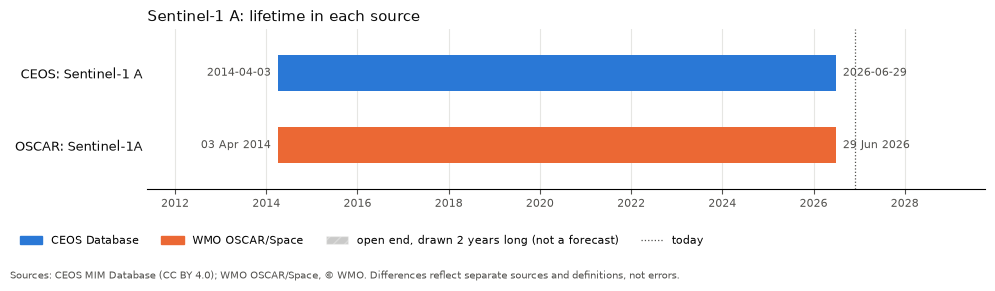

In [11]:
CEOS_COLOUR, OSCAR_COLOUR, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"


def ceos_span(c):
    # (start, end, end is open, start label, end label) from a CEOS record, or None.
    try:
        start = date.fromisoformat(str(c.get("launch_date"))[:10])
    except ValueError:
        return None
    try:
        end = date.fromisoformat(str(c.get("eol_date"))[:10])
    except ValueError:
        end = None
    start_label = str(c.get("launch_date"))[:10]
    if not blank(c.get("launch_date_override")):
        start_label += " (to be determined)"
    return start, end, False, start_label, show(c.get("eol_date"))[:10]


def oscar_span(start_text, end_text):
    start, _, _ = parse_oscar_date(start_text)
    if start is None:
        return None
    end, _, end_open = parse_oscar_date(end_text)
    return start, end, end_open, show(start_text), show(end_text)


def lifetime_chart(c, o):
    rows = [(f"CEOS: {c['mission_acronym']}", ceos_span(c), CEOS_COLOUR, 0.5),
            (f"OSCAR: {o['acronym']}", oscar_span(o.get("launch_date"), o.get("EoL")), OSCAR_COLOUR, 0.5)]

    today = date.today()
    fade = timedelta(days=730)   # drawn length of an open end: a convention, not a prediction
    height_in = 0.5 * len(rows) + 1.9
    fig, ax = plt.subplots(figsize=(10, height_in))
    labels, drawn = [], [today]
    for y, (label, span, colour, height) in enumerate(rows):
        if span is None:
            labels.append(label + "  (no launch date)")
            continue
        labels.append(label)
        start, end, end_open, start_label, end_label = span
        solid_end = end or max(start, today)
        ax.barh(y, (solid_end - start).days, left=start, height=height, color=colour, linewidth=0)
        text_x = solid_end
        if end_open or end is None:
            ax.barh(y, fade.days, left=solid_end, height=height, color=colour, alpha=0.3,
                    hatch="///", edgecolor="white", linewidth=0)
            text_x = solid_end + fade
        drawn += [start, text_x]
        ax.annotate(start_label, (start, y), xytext=(-5, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=8, color=MUTED)
        ax.annotate(end_label or "no end date", (text_x, y), xytext=(5, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=8, color=MUTED)

    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(labels, fontsize=9, color=INK)
    ax.invert_yaxis()
    today_line = ax.axvline(today, color=MUTED, linewidth=0.9, linestyle=":", label="today")
    ax.set_ylim(len(rows) - 0.4, -0.6)
    pad = (max(drawn) - min(drawn)) * 0.2 + timedelta(days=120)   # room for the date labels
    ax.set_xlim(min(drawn) - pad, max(drawn) + pad)
    ax.xaxis_date()
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=MUTED, labelsize=8)
    ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    fig.legend(handles=[Patch(color=CEOS_COLOUR, label="CEOS Database"),
                        Patch(color=OSCAR_COLOUR, label="WMO OSCAR/Space"),
                        Patch(facecolor=MUTED, alpha=0.3, hatch="///", edgecolor="white",
                              label="open end, drawn 2 years long (not a forecast)"),
                        today_line],
               loc="lower left", bbox_to_anchor=(0.01, 0.28 / height_in), ncol=4, frameon=False, fontsize=8)
    ax.set_title(f"{c['mission_acronym']}: lifetime in each source", loc="left", fontsize=11, color=INK)
    fig.text(0.01, 0.06 / height_in, "Sources: CEOS MIM Database (CC BY 4.0); WMO OSCAR/Space, © WMO. "
             "Differences reflect separate sources and definitions, not errors.", fontsize=7.5, color=MUTED)
    plt.tight_layout(rect=(0, 0.6 / height_in, 1, 1))
    plt.show()


require_link()
lifetime_chart(ceos, osc)

## 8. The payload, side by side

CEOS and OSCAR name instruments differently, and neither holds the other's
instrument identifiers, so instruments are paired by name. The `paired by` column
says which rule made each pair:

| Paired by | Meaning |
|---|---|
| `same acronym` | The acronyms are equal ignoring case and punctuation. OSCAR often adds the satellite in brackets, as in "SAR-C (Sentinel-1)"; the bracketed part is ignored. |
| `same words in full name` | The full names contain the same words in any order ("C-Band Synthetic Aperture Radar" and "Synthetic Aperture Radar (C-band)"). |
| `only instrument left on each side (assumed)` | After the two rules above, exactly one instrument remained unpaired on each side. This is an assumption, not a match: check it. |
| `not paired` | No rule applied. The instrument may be absent from the other source, or simply named too differently to pair automatically. |

OSCAR lists instrument start and end dates per satellite; CEOS holds no equivalent
per-satellite instrument dates, so those columns are shown for reference only.

OSCAR's API often returns the same instrument row twice for one satellite, identical
in every value. Those repeats are left out, and the line above the table says how
many were.

In [12]:
def words(text):
    return frozenset(w for w in re.split(r"[^a-z0-9]+", (text or "").lower()) if w)


def without_brackets(text):
    return re.sub(r"\s*\([^)]*\)", "", text or "").strip()


def distinct_oscar_payload(o):
    # OSCAR's API often returns the same instrument row more than once for a satellite. Keep one
    # of each identical row; rows that differ in any value are all kept.
    seen, distinct = set(), []
    for item in o.get("satellite-instruments") or []:
        key = repr(item)
        if key not in seen:
            seen.add(key)
            distinct.append(item)
    return distinct


def pair_payload(ceos_list, oscar_list):
    oscar_left = list(oscar_list)
    pairs, ceos_left = [], []

    def take(c_item, test, label):
        for o_item in oscar_left:
            if test(c_item, o_item["instrument"]):
                oscar_left.remove(o_item)
                pairs.append((c_item, o_item, label))
                return True
        return False

    def same_acronym(c_item, o_inst):
        target = squash(c_item["instrument_acronym"])
        return bool(target) and target in (squash(o_inst["name"]), squash(without_brackets(o_inst["name"])))

    def same_words(c_item, o_inst):
        return bool(words(c_item["full_name"])) and words(c_item["full_name"]) == words(o_inst["fullname"])

    for c_item in ceos_list:
        if not take(c_item, same_acronym, "same acronym"):
            ceos_left.append(c_item)
    still_left = []
    for c_item in ceos_left:
        if not take(c_item, same_words, "same words in full name"):
            still_left.append(c_item)
    if len(still_left) == 1 and len(oscar_left) == 1:
        pairs.append((still_left.pop(), oscar_left.pop(), "only instrument left on each side (assumed)"))
    pairs += [(c_item, None, "not paired") for c_item in still_left]
    pairs += [(None, o_item, "not paired") for o_item in oscar_left]

    rows = []
    for c_item, o_item, label in pairs:
        o_inst = (o_item or {}).get("instrument", {})
        rows.append({
            "CEOS instrument": show((c_item or {}).get("instrument_acronym")),
            "CEOS full name": show((c_item or {}).get("full_name")),
            "OSCAR instrument": show(o_inst.get("name")),
            "OSCAR full name": show(o_inst.get("fullname")),
            "paired by": label,
            "CEOS type": "; ".join((c_item or {}).get("types") or []),
            "OSCAR type": show(o_inst.get("instrumenttype")),
            "OSCAR start": show((o_item or {}).get("start-date")),
            "OSCAR end": show((o_item or {}).get("EoL")),
        })
    return pd.DataFrame(rows, columns=["CEOS instrument", "CEOS full name", "OSCAR instrument",
                                       "OSCAR full name", "paired by", "CEOS type", "OSCAR type",
                                       "OSCAR start", "OSCAR end"])


require_link()
oscar_payload = distinct_oscar_payload(osc)
repeats = len(osc.get("satellite-instruments") or []) - len(oscar_payload)
payload = pair_payload(ceos_instruments, oscar_payload)
print(f"CEOS lists {len(ceos_instruments)} instrument(s); OSCAR lists {len(oscar_payload)}."
      + (f" ({repeats} identical repeated row(s) in OSCAR's answer left out.)" if repeats else ""))
save_csv(with_provenance(payload, ceos, osc), f"ceos-oscar-{slug}-payload.csv")
payload

CEOS lists 1 instrument(s); OSCAR lists 1.


,CEOS instrument,CEOS full name,OSCAR instrument,OSCAR full name,paired by,CEOS type,OSCAR type,OSCAR start,OSCAR end
0,C-Band SAR,C-Band Synthetic Aperture Radar,SAR-C (Sentinel-1),Synthetic Aperture Radar (C-band),same words in full name,Imaging microwave radars,Imaging radar (SAR),06 Jul 2014,29 Jun 2026


## 9. Browse the canonical list and compare any mission

The table below is the CEOS canonical mission list: one row per mission, with the
canonical identifier to use as `MISSION` and whether the record carries a link to
OSCAR. In Colab the table can be searched and sorted.

In [13]:
mission_list = pd.DataFrame({
    "canonical id": [m["slug"] for m in all_ceos],
    "acronym": [m["mission_acronym"] for m in all_ceos],
    "full name": [m["full_name"] for m in all_ceos],
    "agency": [m.get("lead_agency") for m in all_ceos],
    "status": [m.get("status") for m in all_ceos],
    "launch": [m.get("launch_date") for m in all_ceos],
    "OSCAR link": ["yes" if m.get("oscar_id") else "no" for m in all_ceos],
}).sort_values("canonical id").reset_index(drop=True)

print(f"{len(mission_list):,} missions; {(mission_list['OSCAR link'] == 'yes').sum():,} carry a link to OSCAR.")
save_csv(mission_list, "ceos-canonical-missions.csv")
try:
    from google.colab import data_table
    listing = data_table.DataTable(mission_list, include_index=False, num_rows_per_page=10)
except Exception:   # not in Colab, or Colab's table is unavailable: show the first rows instead
    listing = mission_list.head(10)
    print("Showing the first 10 rows. The whole list is in `mission_list`.")
listing

1,200 missions; 563 carry a link to OSCAR.
Showing the first 10 rows. The whole list is in `mission_list`.


,canonical id,acronym,full name,agency,status,launch,OSCAR link
0,3cat-constellation,3Cat Constellation,3Cat (Cube-cat),UPC,Operational (nominal),2018-11-29,no
1,3d-sar,3D-SAR,Sentinel-1 3D-SAR Companion,KappaZeta,Planned,2028-12-31,no
2,3d-winds,3D Winds,Three Dimensional Tropospheric Winds from Space Based Lidar,NASA,Cancelled,2030-01-03,yes
3,aalto-1,Aalto-1,Aalto-1,University of Aalto,Mission complete,2017-06-23,no
4,aausat,AAUSat,Aalborg University CubeSat,Aalborg University,Mission complete,2003-06-30,no
5,ace,ACE,Aerosol Clouds and Ecosystem Mission,NASA,Cancelled,2022-01-03,yes
6,acrimsat,ACRIMSAT,Active Cavity Radiometer Irradiance Monitor,NASA,Mission complete,1999-12-20,yes
7,adeos,ADEOS,Advanced Earth Observing Satellite,JAXA,Mission complete,1996-08-17,yes
8,adeos-ii,ADEOS-II,Advanced Earth Observing Satellite - II,JAXA,Mission complete,2002-12-14,yes
9,aeneas,Aeneas,Aeneas,USC / SERC,Mission complete,2012-09-13,no


The picker below does sections 2 to 8 in one step for whichever mission you choose.
Start typing a name or identifier, pick from the list, and press **Compare**. It
reports shared OSCAR records as section 4 does and, with `SAVE_CSV = True`, saves
the chosen mission's tables. It
needs a live notebook session, so it does not appear when this notebook is only
being viewed on GitHub. A mission with no link to OSCAR is reported as such; to
search for candidates, put it in `MISSION` in section 1 and follow section 5.

In [14]:
def compare_mission(name):
    # Sections 2 to 8 for one mission: resolve, fetch, link, compare, chart, payload.
    ids = get(f"/mission/{name}/identifiers").json()
    c = get(f"/mission/{ids['canonical']['slug']}").json()
    o, how = link_to_oscar(c)
    print(f"CEOS  : {c['mission_acronym']}  (canonical id {c['slug']}; data as of {meta.get('as_of')})")
    print(f"Link  : {how}")
    if o is None:
        return
    print(f"OSCAR : {o['acronym']}  ({OSCAR_SITE}/satellites/view/{o['slug']})")
    report_shared_link(c["slug"], o)
    table = compare_records(c, o)
    save_csv(with_provenance(table, c, o), f"ceos-oscar-{c['slug']}.csv")
    display(tinted(table))
    lifetime_chart(c, o)
    instruments = get(f"/mission/{ids['entity_id']}/instruments").json()["instruments"]
    oscar_rows = distinct_oscar_payload(o)
    left_out = len(o.get("satellite-instruments") or []) - len(oscar_rows)
    payload_table = pair_payload(instruments, oscar_rows)
    print(f"CEOS lists {len(instruments)} instrument(s); OSCAR lists {len(oscar_rows)}."
          + (f" ({left_out} identical repeated row(s) in OSCAR's answer left out.)" if left_out else ""))
    save_csv(with_provenance(payload_table, c, o), f"ceos-oscar-{c['slug']}-payload.csv")
    display(payload_table)


try:
    import ipywidgets as widgets
except ImportError:
    widgets = None
    print("The picker needs the ipywidgets package (included in Colab). "
          "Without it, call compare_mission('landsat-8') in a cell.")

if widgets:
    picker = widgets.Combobox(
        options=[f"{m['slug']}  |  {m['mission_acronym']}" for m in sorted(all_ceos, key=lambda m: m["slug"])],
        placeholder="Type a mission name or identifier", ensure_option=True,
        description="Mission:", layout=widgets.Layout(width="520px"))
    button = widgets.Button(description="Compare", button_style="primary")
    result_area = widgets.Output()

    def on_compare(_):
        result_area.clear_output()
        with result_area:
            if not picker.value:
                print("Choose a mission from the list first.")
                return
            try:
                compare_mission(picker.value.split("  |  ")[0])
            except RuntimeError as exc:
                print(exc)

    button.on_click(on_compare)
    display(widgets.HBox([picker, button]), result_area)

Output()

## 10. Optional: launch and end-of-life dates across every linked mission

Off by default. Set `RUN_BULK = True` in section 1 to run it. It downloads OSCAR's
full satellite list (about three minutes) and applies the section 6 date and status
rules to every CEOS mission that carries an `oscar_id`. The result is a table for
your own analysis, not a chart: set `SAVE_CSV = True` as well to keep it as a CSV
file with one row per mission, both sources' values, the result and the note for
each field.

Two columns are numbers you can sort or filter on in a spreadsheet:
`launch gap (days)` and `end-of-life gap (days)`. Each is the CEOS date minus the
OSCAR date, so a positive number means CEOS is later. A gap is given only where both
sources hold an exact date; it is blank where OSCAR gives a month, a year or a lower
bound, or where the CEOS launch date is a placeholder.

Read the result with the caveats at the top in mind, and three more:

- Only curated links are used here. Missions without an `oscar_id` are counted, not
  matched by name.
- Where several CEOS records share one OSCAR record, each is compared with it, and
  they are listed separately so you can discount them.
- A long list of differences on future missions mostly reflects how each source
  records plans, not a disagreement about facts.

In [15]:
def compare_all_linked():
    oscar_by_id = {sat["id"]: sat for sat in fetch_all_oscar_satellites()}
    rows = []
    for m in all_ceos:
        if not m.get("oscar_id"):
            continue
        sat = oscar_by_id.get(m["oscar_id"])
        if sat is None:
            gone = "no OSCAR record with this number"
            rows.append({"CEOS id": m["slug"], "oscar_id": m["oscar_id"], "CEOS status": m.get("status"),
                         "launch result": gone, "end-of-life result": gone, "status result": gone})
            continue
        placeholder = not blank(m.get("launch_date_override"))
        launch = compare_dates(m.get("launch_date"), sat.get("launch_date"), ceos_placeholder=placeholder)
        eol = compare_dates(m.get("eol_date"), sat.get("EoL"))
        status = compare_grouped(m.get("status"), sat.get("status"), CEOS_PHASE, OSCAR_PHASE, "status")
        rows.append({
            "CEOS id": m["slug"], "oscar_id": m["oscar_id"], "OSCAR slug": sat["slug"],
            "CEOS launch": m.get("launch_date"), "OSCAR launch": sat.get("launch_date"),
            "launch result": launch[0],
            "launch gap (days)": date_gap_days(m.get("launch_date"), sat.get("launch_date"), placeholder),
            "launch note": launch[1],
            "CEOS end of life": m.get("eol_date"), "OSCAR end of life": sat.get("EoL"),
            "end-of-life result": eol[0],
            "end-of-life gap (days)": date_gap_days(m.get("eol_date"), sat.get("EoL")),
            "end-of-life note": eol[1],
            "CEOS status": m.get("status"), "OSCAR status": sat.get("status"),
            "status result": status[0], "status note": status[1],
        })
    table = pd.DataFrame(rows)
    for column in ("launch gap (days)", "end-of-life gap (days)"):
        if column not in table:   # no linked mission found an OSCAR record
            table[column] = pd.NA
        table[column] = table[column].astype("Int64")   # whole days, blank where no exact gap exists
    return table, oscar_by_id


bulk = None
if RUN_BULK:
    bulk, oscar_by_id = compare_all_linked()
    linked_ids = {m["oscar_id"] for m in all_ceos if m.get("oscar_id")}
    print(f"CEOS missions: {len(all_ceos):,}; with an oscar_id: {len(bulk):,}; "
          f"without: {len(all_ceos) - len(bulk):,}")
    print(f"OSCAR satellites: {len(oscar_by_id):,}; pointed at by a CEOS record: "
          f"{len(linked_ids & set(oscar_by_id)):,}")
    shared = bulk[bulk.duplicated("oscar_id", keep=False)].sort_values("oscar_id")
    print(f"CEOS records that share an OSCAR record with another: {len(shared):,} (listed below the counts)")
    display(pd.DataFrame({
        "launch": bulk["launch result"].value_counts(),
        "end of life": bulk["end-of-life result"].value_counts(),
        "status": bulk["status result"].value_counts(),
    }).fillna(0).astype(int))
    display(shared[["oscar_id", "OSCAR slug", "CEOS id"]].reset_index(drop=True))
    bulk_out = bulk.copy()
    bulk_out["CEOS data as of"] = meta.get("as_of")
    bulk_out["retrieved"] = retrieved
    save_csv(bulk_out, "ceos-oscar-all-linked-missions.csv")
else:
    print("Skipped. Set RUN_BULK = True in section 1 to run this section.")

Skipped. Set RUN_BULK = True in section 1 to run this section.


In [16]:
def largest_gap_first(table, column):
    # Rows with no exact day gap (OSCAR gives a month, a year or a lower bound) go last; their
    # difference is described in the note column. Ties keep canonical-id order.
    ordered = table.sort_values("CEOS id").sort_values(
        column, key=lambda gaps: gaps.abs(), ascending=False, na_position="last", kind="stable")
    blank = int(ordered[column].isna().sum())
    if blank:
        print(f"{blank:,} of these have no exact day gap and are listed last; see the note column.")
    return ordered


# The launch dates that differ, for missions both sources regard as launched. Largest gap first.
if RUN_BULK:
    launched = bulk[(bulk["launch result"] == "differs")
                    & bulk["CEOS status"].map(CEOS_PHASE).isin(["operating", "ended", "commissioning"])
                    & bulk["OSCAR status"].map(OSCAR_PHASE).isin(["operating", "ended", "commissioning"])]
    print(f"Launch date differs, launched in both sources: {len(launched):,} mission(s)")
    display(largest_gap_first(launched, "launch gap (days)")[
        ["CEOS id", "OSCAR slug", "CEOS launch", "OSCAR launch", "launch gap (days)", "launch note",
         "CEOS status", "OSCAR status"]].reset_index(drop=True))

End-of-life dates are compared the same way, but only for missions that **both**
sources regard as ended. For a mission still flying, an end-of-life date is a plan
or an estimate in each source, and a difference between two estimates says little.

In [17]:
# The end-of-life dates that differ, for missions both sources regard as ended. Largest gap first.
if RUN_BULK:
    ended = bulk[(bulk["end-of-life result"] == "differs")
                 & (bulk["CEOS status"].map(CEOS_PHASE) == "ended")
                 & (bulk["OSCAR status"].map(OSCAR_PHASE) == "ended")]
    print(f"End-of-life date differs, ended in both sources: {len(ended):,} mission(s)")
    display(largest_gap_first(ended, "end-of-life gap (days)")[
        ["CEOS id", "OSCAR slug", "CEOS end of life", "OSCAR end of life", "end-of-life gap (days)",
         "end-of-life note", "CEOS status", "OSCAR status"]].reset_index(drop=True))

## What to do with a difference

- Open both records and read them: the OSCAR page link is printed in section 7, and
  the CEOS record is at `https://database.eohandbook.com` or in the
  [EO Capabilities Explorer](https://ceos-capabilities.org).
- If you believe the CEOS value is out of date, tell us at
  support@ceos-capabilities.org, with the source for the correct value.
- If you believe the OSCAR value is out of date, use the contact route on the
  [OSCAR/Space site](https://space.oscar.wmo.int).
- If a link or a pairing made by this notebook looks wrong, please open an issue at
  https://github.com/ceos-capabilities/examples/issues.

**Sources.** CEOS MIM Database, https://database.eohandbook.com (CC BY 4.0).
WMO OSCAR/Space, https://space.oscar.wmo.int, © World Meteorological Organization.